# Clustering de distritos (caso 1.3) — modelo baseline

Primer modelo del caso 1.3: un **clustering baseline** de los 21 distritos de Madrid para la segmentación socio-sanitaria. Es un punto de partida para discutir en el grupo, no el modelo final: por eso se queda en k-means + jerárquico con elección de k justificada, y cada decisión queda escrita.

- **Entrada:** `tabla_distritos.csv` (valores reales) y `tabla_distritos_norm.csv` (misma tabla normalizada min-max 0-1, la entrada del clustering). Ambas salen de `cruces_datasets.ipynb`.
- **Por qué normalizado:** k-means usa distancias euclídeas, así que sin escalar la renta (~40.000) aplastaría a los porcentajes (~0-30). La normalización min-max ya estaba hecha y validada en la fase de limpieza.
- **Qué NO es esto:** no es una conclusión de ahorro ni el modelo definitivo. Es el baseline sobre el que iterar (otras k, DBSCAN, otras variables).

## 1. Carga y selección de variables

Regla aplicada, en este orden:

1. **Fuera las 3 columnas con datos desconocidos** (`unidades_samur`, `num_hospitales_cat`, `camas_hospital`): tienen 7 celdas vacías (Puente y Villa de Vallecas, camas de Arganzuela) pendientes de confirmar con Bluetab, y el criterio acordado es no imputar lo que no se sabe. Está documentado en `README_recursos_samur.md`.
2. **Fuera `num_bases_samur`**: es oferta, y la oferta no debería decidir cómo se agrupan los distritos por su perfil socio-sanitario. Se usa después, en la comprobación de oferta vs demanda por clúster.
3. **Fuera columnas redundantes por construcción**: `poblacion` y `superficie_km2` (su información ya está en `densidad_hab_km2`) y `n_activaciones` (ya está en `activaciones_por_1000hab`, que es comparable entre distritos).
4. **Fuera las muy correlacionadas entre sí**: con 21 distritos, meter dos columnas casi idénticas cuenta esa dimensión dos veces. Se revisan los pares con |r| > 0,85 y se queda una representante por grupo.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

df = pd.read_csv('tabla_distritos.csv')
nrm = pd.read_csv('tabla_distritos_norm.csv')
print(df.shape, nrm.shape)

# huecos por columna (de donde sale la regla 1)
huecos = df.drop(columns=['distrito_id', 'distrito']).isna().sum()
print('\nColumnas con huecos:')
print(huecos[huecos > 0])

(21, 22) (21, 22)

Columnas con huecos:
unidades_samur        2
num_hospitales_cat    2
camas_hospital        3
dtype: int64


In [2]:
# regla 4: pares muy correlacionados entre las candidatas
candidatas = ['densidad_hab_km2', 'renta_media_hogar', 'edad_media', 'pct_mayores_65',
              'pct_extranjeros', 'tasa_paro', 'indice_vulnerabilidad', 'num_centros_salud',
              'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta',
              'edad_media_paciente', 'tiempo_respuesta_medio_min']
corr = df[candidatas].corr().abs()
pares = [(a, b, round(corr.loc[a, b], 3))
         for i, a in enumerate(candidatas) for b in candidatas[i+1:]
         if corr.loc[a, b] > 0.85]
print('Pares con |r| > 0,85:')
for a, b, r in pares:
    print(f'  {a} ~ {b}: r = {r}')

# De cada grupo se queda la mas interpretable: renta (eje economico) y pct_mayores_65 (eje edad)
variables = ['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros',
             'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
print(f'\nVariables finales del clustering ({len(variables)}):')
for v in variables:
    print(' -', v)

X = nrm[variables].to_numpy()
assert not np.isnan(X).any(), 'no debe haber huecos en la matriz del clustering'

Pares con |r| > 0,85:
  renta_media_hogar ~ tasa_paro: r = 0.935
  renta_media_hogar ~ indice_vulnerabilidad: r = 0.956
  edad_media ~ pct_mayores_65: r = 0.976
  tasa_paro ~ indice_vulnerabilidad: r = 0.985

Variables finales del clustering (10):
 - densidad_hab_km2
 - renta_media_hogar
 - pct_mayores_65
 - pct_extranjeros
 - num_centros_salud
 - parques_m2_habitante
 - activaciones_por_1000hab
 - pct_prioridad_alta
 - edad_media_paciente
 - tiempo_respuesta_medio_min


Se ve que `renta_media_hogar`, `tasa_paro` e `indice_vulnerabilidad` miden casi lo mismo (r hasta 0,98), y `edad_media` y `pct_mayores_65` también (r = 0,98). Se conservan `renta_media_hogar` como representante del eje económico y `pct_mayores_65` como representante del eje de edad, por ser las más directas de explicar en la presentación. Las demás se descartan solo del clustering: siguen en la tabla y se usan al describir los clústeres.

## 2. Elección de k: codo, silueta y acuerdo entre dos métodos

Se prueban dos algoritmos: **k-means** (el sugerido en el enunciado) y **agrupamiento jerárquico con enlace Ward** (que también minimiza varianza interna, así que son comparables). Para k de 2 a 8 se miran tres cosas:

- **Codo (inercia de k-means):** dónde deja de bajar fuerte la varianza interna.
- **Silueta:** cuánto se parece cada distrito a su clúster frente al vecino más cercano (mayor = mejor separado).
- **ARI entre k-means y Ward:** si dos métodos distintos coinciden en la partición, la estructura es más creíble.

 k  inercia  silueta_kmeans  silueta_ward  ARI_kmeans_ward
 2    10.51           0.210         0.214            0.241
 3     7.66           0.233         0.239            0.748
 4     6.53           0.182         0.219            0.656
 5     5.59           0.179         0.219            0.506
 6     4.69           0.175         0.216            0.450
 7     3.96           0.171         0.148            0.466
 8     3.23           0.161         0.168            0.301


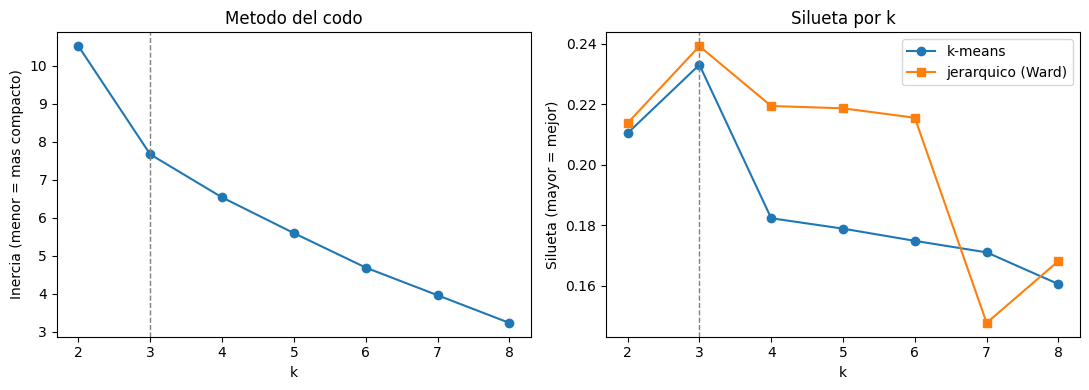

In [3]:
ks = range(2, 9)
inercias, sil_km, sil_hc, aris = [], [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    inercias.append(km.inertia_)
    sil_km.append(silhouette_score(X, km.labels_))
    sil_hc.append(silhouette_score(X, hc.labels_))
    aris.append(adjusted_rand_score(km.labels_, hc.labels_))

res = pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 2),
                    'silueta_kmeans': np.round(sil_km, 3),
                    'silueta_ward': np.round(sil_hc, 3),
                    'ARI_kmeans_ward': np.round(aris, 3)})
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inercias, 'o-', color='#1f77b4')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inercia (menor = mas compacto)')
ax[0].set_title('Metodo del codo')
ax[0].axvline(3, color='grey', ls='--', lw=1)
ax[1].plot(list(ks), sil_km, 'o-', label='k-means', color='#1f77b4')
ax[1].plot(list(ks), sil_hc, 's-', label='jerarquico (Ward)', color='#ff7f0e')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silueta (mayor = mejor)')
ax[1].set_title('Silueta por k'); ax[1].legend()
ax[1].axvline(3, color='grey', ls='--', lw=1)
plt.tight_layout(); plt.show()

**Lectura:** el codo está en k = 3-4; la silueta es máxima en **k = 3** para los dos métodos (0,233 k-means, 0,239 Ward); y k = 3 es también donde más coinciden k-means y Ward (ARI = 0,75, el máximo). Las tres señales apuntan al mismo sitio, así que **el baseline se queda con k = 3**. k = 4 (que separa Centro-Arganzuela-Tetuán del resto del cinturón) queda anotada como alternativa para discutir.

Con 21 filas la silueta no va a dar valores altos; lo importante es la comparación entre k, no el valor absoluto.

## 3. Modelo final: k-means con k = 3

`n_init=50` para que no dependa de una única inicialización aleatoria, y `random_state=42` para que sea reproducible.

In [4]:
k_final = 3
km = KMeans(n_clusters=k_final, n_init=50, random_state=42).fit(X)
df['cluster'] = km.labels_

# nombres legibles segun el perfil que sale abajo
nombres = {0: 'Acomodado y envejecido', 1: 'Denso y vulnerable', 2: 'Periferico y disperso'}
df['cluster_nombre'] = df['cluster'].map(nombres)

for c in range(k_final):
    d = df[df.cluster == c]
    print(f"Cluster {c} - {nombres[c]} ({len(d)} distritos):")
    print('  ' + ', '.join(d['distrito'].str.title()))
    print()

Cluster 0 - Acomodado y envejecido (5 distritos):
  Retiro, Salamanca, Chamartin, Chamberi, Moratalaz

Cluster 1 - Denso y vulnerable (10 distritos):
  Centro, Arganzuela, Tetuan, Latina, Carabanchel, Usera, Puente De Vallecas, Ciudad Lineal, Villaverde, San Blas-Canillejas

Cluster 2 - Periferico y disperso (6 distritos):
  Fuencarral-El Pardo, Moncloa-Aravaca, Hortaleza, Villa De Vallecas, Vicalvaro, Barajas



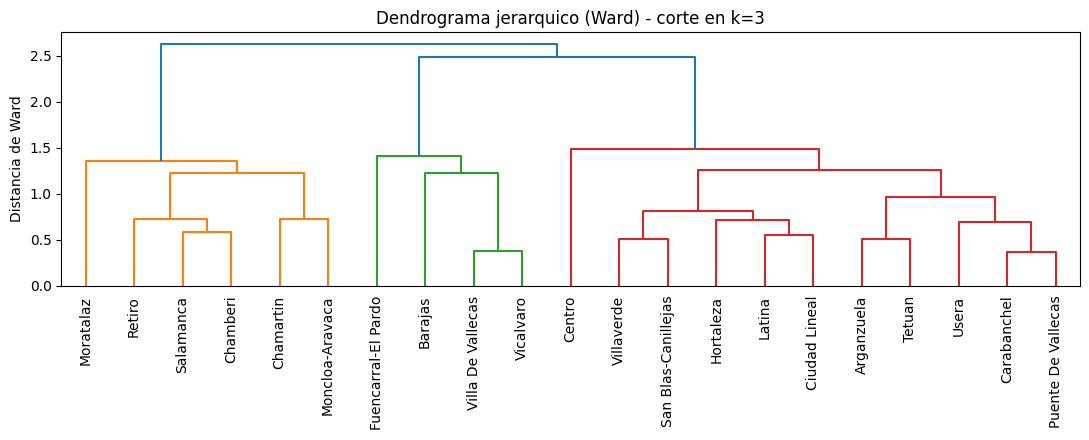

In [5]:
# dendrograma Ward: se ve la estructura que resume k-means
Z = linkage(X, method='ward')
plt.figure(figsize=(11, 4.5))
dendrogram(Z, labels=df['distrito'].str.title().tolist(), leaf_rotation=90,
           color_threshold=Z[-(k_final-1), 2])
plt.title('Dendrograma jerarquico (Ward) - corte en k=3')
plt.ylabel('Distancia de Ward')
plt.tight_layout(); plt.show()

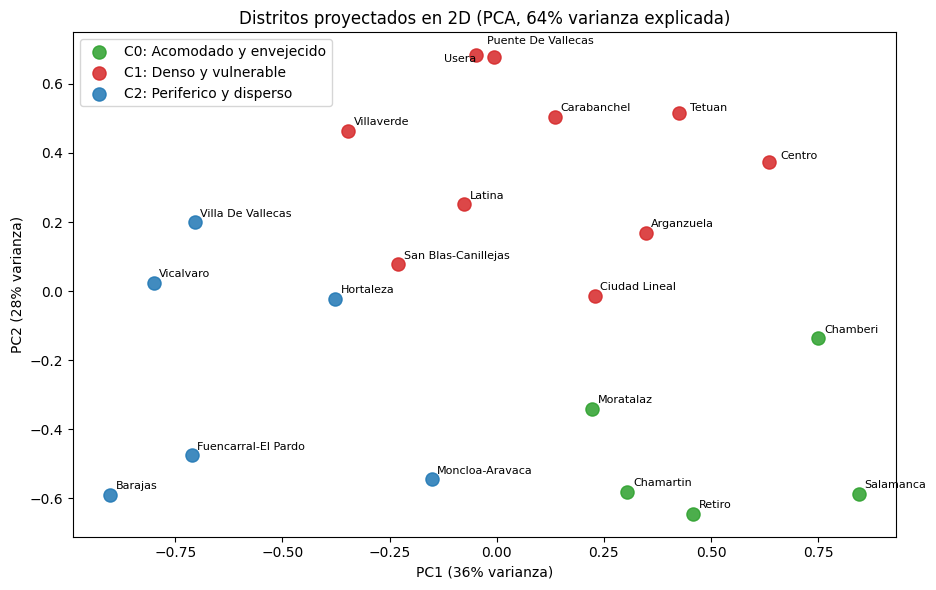

In [6]:
# vista 2D (PCA) coloreada por cluster: PCA solo para dibujar, no para decidir
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
plt.figure(figsize=(9.5, 6))
colores = ['#2ca02c', '#d62728', '#1f77b4']
for c in range(k_final):
    m = df.cluster.to_numpy() == c
    plt.scatter(P[m, 0], P[m, 1], s=90, color=colores[c], label=f'C{c}: {nombres[c]}', alpha=0.85)
offsets = {'PUENTE DE VALLECAS': (8, 8), 'USERA': (-36, -4), 'CENTRO': (8, 2), 'TETUAN': (8, 2)}
for i, d in enumerate(df['distrito']):
    plt.annotate(d.title(), (P[i, 0], P[i, 1]), fontsize=8,
                 xytext=offsets.get(d, (4, 4)), textcoords='offset points')
var_exp = pca.explained_variance_ratio_.sum() * 100
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% varianza)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% varianza)')
plt.title(f'Distritos proyectados en 2D (PCA, {var_exp:.0f}% varianza explicada)')
plt.legend(); plt.tight_layout(); plt.show()

## 4. Perfil de cada clúster (valores reales, no normalizados)

Los clústeres se describen con los valores reales de la tabla, que es lo que se puede contar en la presentación.

In [7]:
cols_desc = ['renta_media_hogar', 'tasa_paro', 'indice_vulnerabilidad', 'pct_mayores_65',
             'pct_extranjeros', 'densidad_hab_km2', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
perfil = df.groupby('cluster_nombre')[cols_desc].mean().round(2)
perfil.loc['MEDIA MADRID'] = df[cols_desc].mean().round(2)
print(perfil.T.to_string())

cluster_nombre              Acomodado y envejecido  Denso y vulnerable  Periferico y disperso  MEDIA MADRID
renta_media_hogar                         56418.60            33037.20               43906.83      41709.81
tasa_paro                                     7.10               12.64                   9.92         10.54
indice_vulnerabilidad                         0.26                0.59                   0.42          0.46
pct_mayores_65                               24.72               18.14                  15.50         18.95
pct_extranjeros                              11.72               20.22                  14.45         16.55
densidad_hab_km2                          21956.68            17689.91                2654.98      14410.11
activaciones_por_1000hab                     45.46               52.13                  39.89         47.04
pct_prioridad_alta                           29.30               29.76                  29.84         29.67
edad_media_paciente         

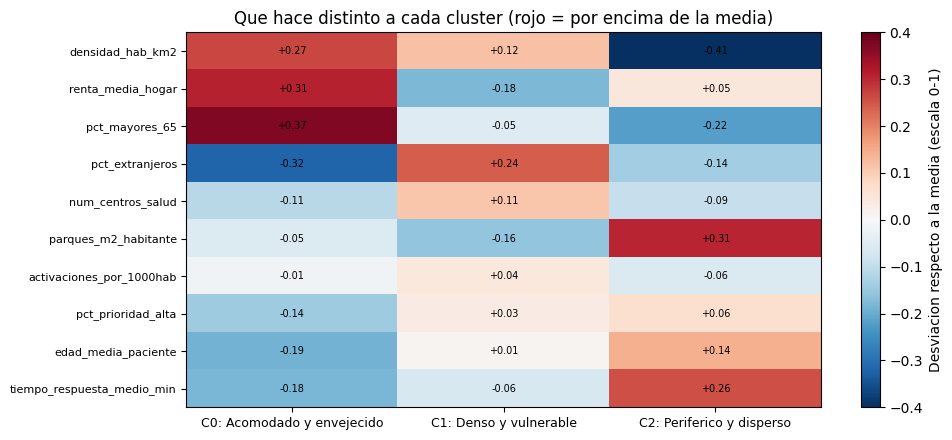

In [8]:
# que variables hacen distinto a cada cluster (media normalizada vs media global)
med_global = nrm[variables].mean()
medias = nrm[variables].assign(cluster=df.cluster).groupby('cluster').mean()
dif = (medias - med_global)

plt.figure(figsize=(10, 4.5))
im = plt.imshow(dif.T, cmap='RdBu_r', vmin=-0.4, vmax=0.4, aspect='auto')
plt.colorbar(im, label='Desviacion respecto a la media (escala 0-1)')
plt.yticks(range(len(variables)), variables, fontsize=8)
plt.xticks(range(k_final), [f'C{c}: {nombres[c]}' for c in range(k_final)], fontsize=9)
for i in range(len(variables)):
    for c in range(k_final):
        plt.text(c, i, f'{dif.T.iloc[i, c]:+.2f}', ha='center', va='center', fontsize=7)
plt.title('Que hace distinto a cada cluster (rojo = por encima de la media)')
plt.tight_layout(); plt.show()

**Cómo se leen los tres clústeres:**

- **C0 — Acomodado y envejecido** (Retiro, Salamanca, Chamartín, Chamberí, Moratalaz): renta muy por encima de la media (56.400 € frente a 41.700 €), paro bajo (7,1 %), el más envejecido (24,7 % de mayores de 65) y el de menor respuesta media (7,6 min).
- **C1 — Denso y vulnerable** (Centro, Arganzuela, Tetuán, Latina, Carabanchel, Usera, Puente de Vallecas, Ciudad Lineal, Villaverde, San Blas-Canillejas): el más poblado en total, renta baja (33.000 €), paro alto (12,6 %), más población extranjera (20,2 %) y donde se concentra la mayor parte de la demanda.
- **C2 — Periférico y disperso** (Fuencarral-El Pardo, Moncloa-Aravaca, Hortaleza, Villa de Vallecas, Vicálvaro, Barajas): densidad muy baja (2.650 hab/km² frente a 14.400 de media), mucho parque, y **el peor tiempo medio de respuesta: 9,9 min frente a 8,6 de media** (Barajas 12,0, Villa de Vallecas 10,2 y Vicálvaro 10,1 son los tres distritos más lentos de Madrid).

Ojo con Centro: su tasa de activaciones por 1.000 hab (147,9) es casi el triple que la del segundo distrito, y ya vimos en el EDA que probablemente recoge demanda de visitantes y ocio nocturno, no de residentes. Forma parte del C1, pero es un distrito atípico dentro de él.

## 5. Oferta vs demanda por clúster

Aquí es donde el clustering se conecta con el objetivo práctico (usar recursos donde más falta hace). Solo se usa `num_bases_samur`, que está completa; las otras tres columnas de recursos siguen con huecos pendientes de Bluetab y **no se usan** (ni siquiera como cero).

                        distritos  activaciones  poblacion  bases_samur  centros_salud  activaciones_por_1000hab  activaciones_por_base  tiempo_respuesta_medio_min
cluster_nombre                                                                                                                                                     
Acomodado y envejecido          5         30241     647506            1           30.0                      46.7                30241.0                        7.60
Denso y vulnerable             10         92262    1866858            9           80.0                      49.4                10251.0                        8.24
Periferico y disperso           6         28527     795324            5           37.0                      35.9                 5705.0                        9.94


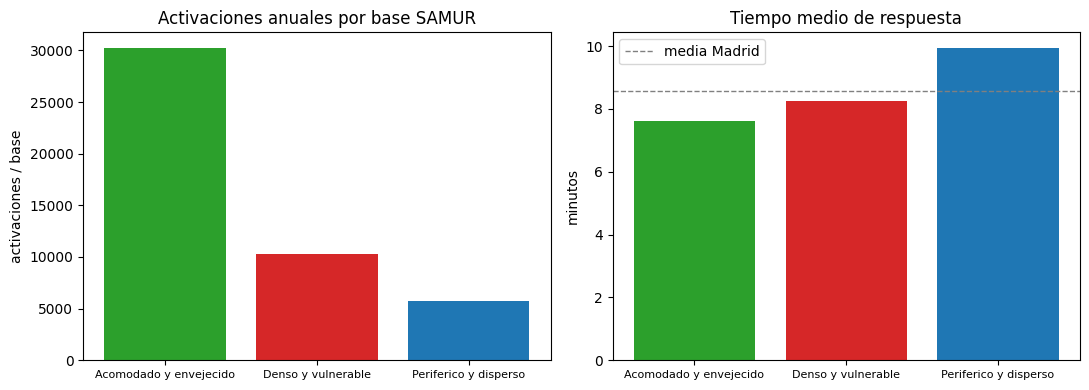

Distritos con recursos aun desconocidos (no se usan arriba):
          distrito        cluster_nombre
        ARGANZUELA    Denso y vulnerable
PUENTE DE VALLECAS    Denso y vulnerable
 VILLA DE VALLECAS Periferico y disperso


In [9]:
oferta = df.groupby('cluster_nombre').agg(
    distritos=('distrito', 'count'),
    activaciones=('n_activaciones', 'sum'),
    poblacion=('poblacion', 'sum'),
    bases_samur=('num_bases_samur', 'sum'),
    centros_salud=('num_centros_salud', 'sum'))
oferta['activaciones_por_1000hab'] = (oferta['activaciones'] / oferta['poblacion'] * 1000).round(1)
oferta['activaciones_por_base'] = (oferta['activaciones'] / oferta['bases_samur']).round(0)
tiempo = df.groupby('cluster_nombre')['tiempo_respuesta_medio_min'].mean().round(2)
oferta['tiempo_respuesta_medio_min'] = tiempo
print(oferta.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(oferta.index, oferta['activaciones_por_base'], color=['#2ca02c', '#d62728', '#1f77b4'])
ax[0].set_title('Activaciones anuales por base SAMUR'); ax[0].set_ylabel('activaciones / base')
ax[0].tick_params(axis='x', labelsize=8)
ax[1].bar(oferta.index, oferta['tiempo_respuesta_medio_min'], color=['#2ca02c', '#d62728', '#1f77b4'])
ax[1].axhline(df['tiempo_respuesta_medio_min'].mean(), color='grey', ls='--', lw=1, label='media Madrid')
ax[1].set_title('Tiempo medio de respuesta'); ax[1].set_ylabel('minutos'); ax[1].legend()
ax[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

print('Distritos con recursos aun desconocidos (no se usan arriba):')
desc = df[df[['unidades_samur', 'num_hospitales_cat', 'camas_hospital']].isna().any(axis=1)]
print(desc[['distrito', 'cluster_nombre']].to_string(index=False))

**Lectura:**

- El **C1 (denso y vulnerable)** concentra ~92.300 activaciones al año, el 61 % del total, con la tasa por habitante más alta (49,4 por 1.000 hab, inflada por Centro, que recoge mucha demanda de no residentes). Sus 9 bases soportan ~10.300 activaciones/base al año.
- El **C0 (acomodado y envejecido)** llama la atención por otro motivo: 5 distritos con ~30.200 activaciones al año y **una sola base SAMUR** en todo el clúster (Chamartín). Es la mayor carga por base con diferencia, aunque sus tiempos de respuesta son los mejores (7,6 min): la dependencia de una única base es un riesgo a vigilar, no un problema medido.
- El **C2 (periférico)** tiene la tasa por habitante más baja (35,9) pero el peor tiempo de respuesta (9,9 min): ahí el problema es la distancia, no el volumen.

Ojo al interpretar las bases: una base no atiende solo a su distrito (cubren zonas próximas), así que los ratios son orientativos. Y estas lecturas son del baseline con la oferta incompleta (faltan unidades, hospitales y camas de 3 distritos): sirven para orientar, no para afirmar dónde falta cobertura.

## 6. Limitaciones y siguientes pasos

**Limitaciones del baseline:**

- Son 21 filas: un distrito atípico (Centro) mueve mucho. Por eso se evitaron columnas duplicadas y se exigió que k-means y Ward coincidieran.
- k-means asume clústeres redondos y usa distancias; si la estructura real es otra, no la va a encontrar.
- La oferta está incompleta (VALLECAS ambiguo, camas sin dato): la comprobación oferta-demanda es provisional hasta que Bluetab confirme.
- Es un modelo descriptivo, no predictivo: no dice qué pasará, solo cómo se parecen los distritos hoy.

**Siguientes pasos propuestos:**

1. Resolver con Bluetab los recursos desconocidos y repetir la comprobación oferta-demanda completa.
2. Probar k = 4 (separa Centro-Arganzuela-Tetuán) y DBSCAN, que sugiere el enunciado, comparando con este baseline.
3. Si el grupo lo ve bien, llevar los 3 perfiles a las diapositivas con el mapa de distritos ya hecho en el EDA.